## Implémentation d'un MLP
Dans ce TP, nous allons implémenter un perceptron multicouche (MLP) pour résoudre un problème de classification non linéaire à partir du jeu de données synthétique make_moons.
Contrairement au TP précédent où le perceptron simple a été implémenté from scratch, nous utiliserons ici les outils de TensorFlow / Keras afin de construire le réseau, définir les couches denses, appliquer les fonctions d’activation et entraîner le modèle.

In [1]:
#importation des bibliothèques
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

**TensorFlow** est une bibliothèque de deep learning qui permet de définir, entraîner et optimiser des modèles neuronaux de manière efficace.


**Keras**, intégré à TensorFlow, fournit une interface simple et intuitive pour construire des réseaux de neurones en empilant des couches (layers) et en gérant automatiquement l’apprentissage.

[Tensorflow site](https://www.tensorflow.org/)

In [2]:
#Création d'un dataset synthétique
X, y = make_moons(n_samples=2000, noise=0.25, random_state=42)

# split train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

In [3]:
#Normalisation des data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

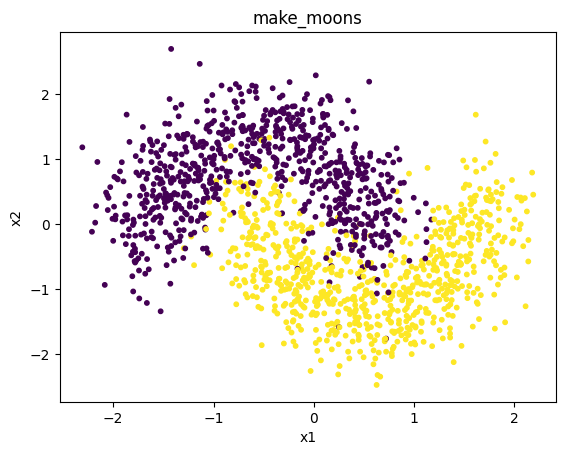

In [5]:
#Visualisation des donnees
plt.figure()
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, s=10)
plt.title("make_moons")
plt.xlabel("x1"); plt.ylabel("x2")
plt.show()

In [30]:
#Construction du modele
model = keras.Sequential([
    layers.Input(shape=(2,)),
    layers.Dense(8, activation="sigmoid"),
    layers.Dense(8, activation="sigmoid"),
    layers.Dense(1, activation="sigmoid")
])

- keras.Sequential([...]) : crée un modèle où les couches sont empilées séquentiellement ; la sortie d’une couche devient l’entrée de la suivante.
- layers.Input(shape=(2,)) : définit la dimension des données d’entrée (ici 2 caractéristiques).
- layers.Dense(...) : correspond à une couche entièrement connectée et constituée de 8 neurones; chaque neurone calcule une combinaison linéaire des entrées ( $z = W^T x + b$), comme dans le perceptron simple.
- activation="..." : applique une fonction d’activation au résultat linéaire afin d’introduire la non-linéarité nécessaire pour apprendre des frontières de décision complexes.
- Dense(1, activation="sigmoid") (couche de sortie) : renvoie une probabilité comprise entre 0 et 1, adaptée à une tâche de classification binaire.

In [31]:
#compilation
model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.1),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


- optimizer : C'est l'algorithme qui va ajuster les poids du réseau pour minimiser l'erreur.

SGD (Stochastic Gradient Descent) : La méthode la plus fondamentale. [Autres optimizer](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers)
- learning_rate=0.1 : La vitesse d'apprentissage - plus c'est grand, plus on modifie les poids rapidement
- loss : La fonction qui mesure l'erreur du modèle.

binary_crossentropy : Utilisée pour la classification binaire (2 classes) [Autres Loss](https://www.tensorflow.org/api_docs/python/tf/keras/losses)


In [32]:
# Entrainement du modele
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=1
)


Epoch 1/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5175 - loss: 0.6916 - val_accuracy: 0.7733 - val_loss: 0.6845
Epoch 2/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7285 - loss: 0.6832 - val_accuracy: 0.7500 - val_loss: 0.6806
Epoch 3/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7034 - loss: 0.6769 - val_accuracy: 0.7800 - val_loss: 0.6701
Epoch 4/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7792 - loss: 0.6671 - val_accuracy: 0.7633 - val_loss: 0.6625
Epoch 5/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8170 - loss: 0.6534 - val_accuracy: 0.7900 - val_loss: 0.6456
Epoch 6/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8191 - loss: 0.6358 - val_accuracy: 0.7800 - val_loss: 0.6323
Epoch 7/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8320 - loss: 0.6135 - val_accuracy: 0.7833 - val_loss: 0.6064
Epoch 8/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8057 - loss: 0.5887 - val_accuracy: 0.7833 - val_loss:

In [33]:
# Evaluation du modele
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.3f}")

Test accuracy: 0.880


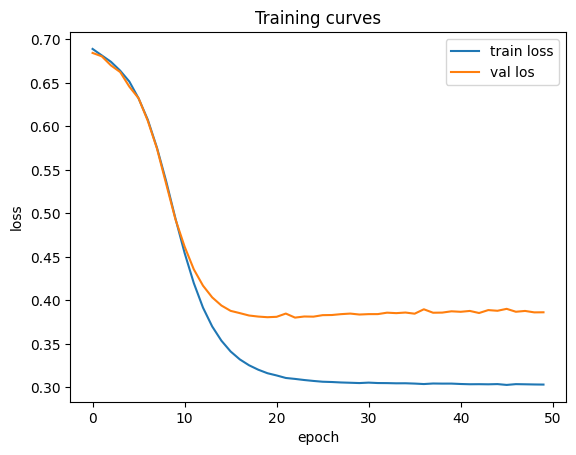

In [34]:
# Visualisation des courbes d'apprentissage
plt.figure()
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val los")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.title("Training curves")
plt.show()

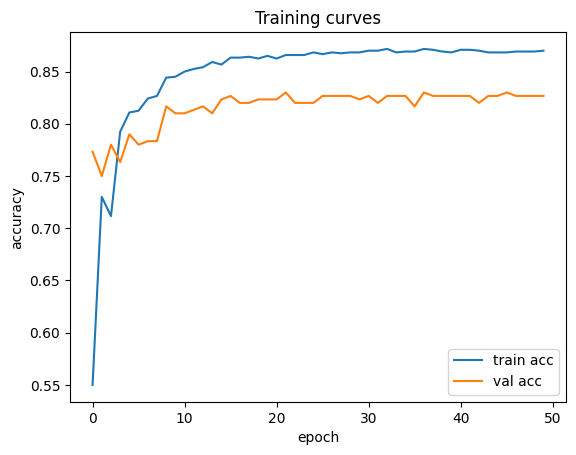

In [35]:
# Visualisation des courbes d'apprentissage
plt.figure()
plt.plot(history.history["accuracy"], label="train acc")
plt.plot(history.history["val_accuracy"], label="val acc")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.legend()
plt.title("Training curves")
plt.show()


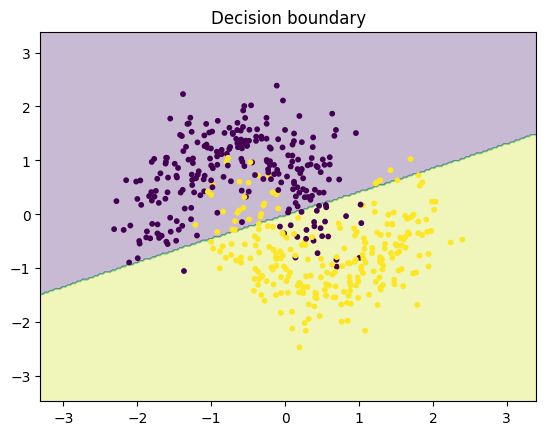

In [36]:
# Visualisation de la frontière de décision
def plot_decision_boundary(model, X, y, steps=200):
    x_min, x_max = X[:, 0].min() - 1.0, X[:, 0].max() + 1.0
    y_min, y_max = X[:, 1].min() - 1.0, X[:, 1].max() + 1.0

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, steps),
        np.linspace(y_min, y_max, steps)
    )
    grid = np.c_[xx.ravel(), yy.ravel()]

    # prédiction proba -> classe
    probs = model.predict(grid, verbose=0).reshape(xx.shape)
    preds = (probs >= 0.5).astype(int)

    plt.figure()
    plt.contourf(xx, yy, preds, alpha=0.3)
    plt.scatter(X[:, 0], X[:, 1], c=y, s=10)
    plt.title("Decision boundary")
    plt.show()

plot_decision_boundary(model, X_test, y_test)


## Expérimentation et amélioration du modèle

À partir du modèle de base, proposez différentes modifications afin d’observer leur impact sur l’apprentissage, la frontière de décision et la performance du réseau.

Essayez notamment les expérimentations suivantes :

- Augmenter la capacité du modèle
   - ajouter des neurones dans les couches cachées
   - ajouter une ou plusieurs couches cachées supplémentaires
   - Changer la fonction d’activation: comparer sigmoid, tanh, relu observer l’effet sur la vitesse de convergence et la frontière de décision. [les fonctions d'activations](https://www.tensorflow.org/api_docs/python/tf/keras/activations)
- Modifier le processus d’optimisation
     - tester différents optimiseurs (SGD, Adam)
     - expérimenter plusieurs valeurs du learning rate
- Tester Batch Normalization
observer son effet sur la stabilité et la vitesse d’apprentissage. [Batch Normalization documentation](https://www.tensorflow.org/api_docs/python/tf/keras/layers/BatchNormalization)
- Tester Dropout
analyser son impact sur la généralisation et vérifier s’il améliore ou dégrade les performances. [Drop out documentation](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Dropout)

Pour chaque modification, essayez d’analyser :
- l’évolution des courbes d’apprentissage
- la frontière de décision
- la performance sur les données de test
- les éventuels signes de sous-apprentissage ou de surapprentissage


Testez les connaissances apprises sur un vrai dataset. ( Exemple red wine dataset)